In [1]:
import astrolabe as ab

In [2]:
# Transcripts are streamed and stored in mdata['xenium'].uns['transcripts'] automatically.
data = ab.io.read_xenium('output-XETG00659__0076505__76505_region_1__20260403__201533', morphology_image=True)
ab.summary(data)

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)


MuData Summary
==================================================
Modalities:
  xenium (default): 162,345 cells × 9,872 vars, 4821 control probes
Extent: x=[6, 7867] µm  y=[88, 5749] µm
Libraries (1):
  output-XETG00659__0076505__76505_region_1__20260403__201533: C:\Users\Austin\PycharmProjects\astrolabe\output-XETG00659__0076505__76505_region_1__20260403__201533  (1 image(s))
Stats: mean area=82.1 µm²
Obs columns:
  QC: cell_area, nucleus_area, transcript_counts, nucleus_count
  Other: control_probe_counts, control_codeword_counts
Graph/seg: cell_boundaries, nucleus_boundaries

## QC Metrics

In [ ]:
# Xenium probe-type QC first: computes per-cell control probe counts and flags
# control features in var['is_control']. It never removes them from var —
# use ab.pipeline.filter_xenium or pp.filter_genes(exclude_controls=True) for that.
ab.pp.calculate_xenium_qc_metrics(data)
data['xenium'].obs[['unassigned_codeword_total', 'negative_control_probe_total',
                     'pct_any_negative_control_probes']].describe()

In [ ]:
# General per-cell and per-gene QC metrics — control probes are still present in var
# at this point (calculate_xenium_qc_metrics only flags them, never removes them).
ab.pp.calculate_qc_metrics(data)
data['xenium'].obs.head()

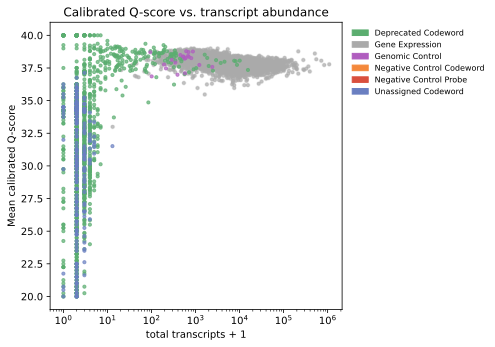

In [5]:
# Mean calibrated Q-score vs. log transcript abundance for gene expression probes.
# Uses mean_qv computed by calculate_xenium_qc_metrics and total_counts from calculate_qc_metrics.
ab.pl.gene_qv_scatter(data)

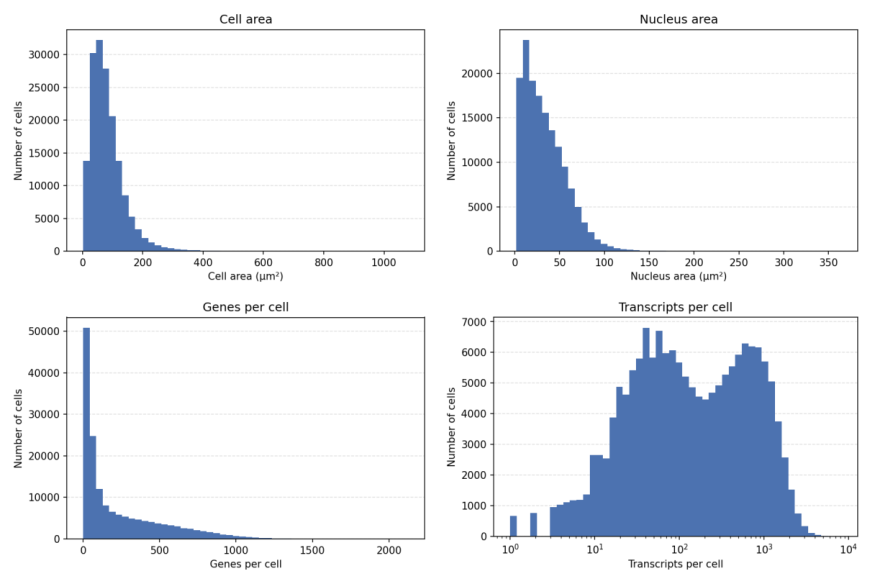

In [6]:
# Cell/nucleus area, genes per cell, and transcripts per cell.
# Pass vlines= to overlay filter thresholds (e.g. vlines=[10] for min_counts=10).
(
    ab.pl.cell_area_histogram(data)
    | ab.pl.nucleus_area_histogram(data)
) / (
    ab.pl.genes_per_cell_histogram(data)
    | ab.pl.transcripts_per_cell_histogram(data)
)

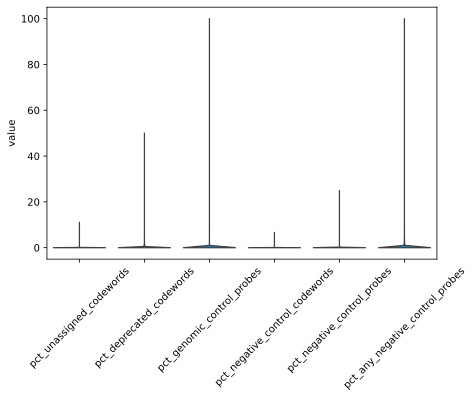

In [7]:
# Per-cell fraction of counts from each control probe category.
ab.pl.violin(
    data,
    ['pct_unassigned_codewords', 'pct_deprecated_codewords',
     'pct_genomic_control_probes', 'pct_negative_control_codewords',
     'pct_negative_control_probes', 'pct_any_negative_control_probes'],
    stripplot=False,
    rotation=45,
)

## Spatial Plots

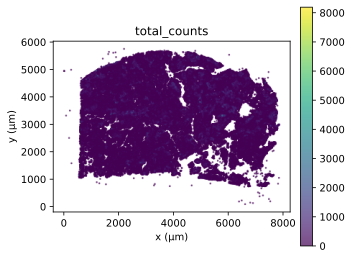

In [8]:
# Total transcript counts per cell — reveals tissue structure and cell density gradients.
ab.pl.points(data, color='total_counts')

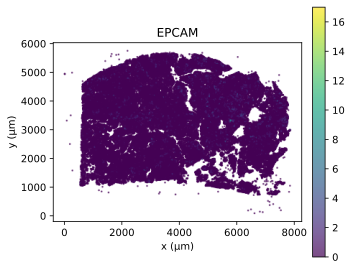

In [9]:
# Single marker gene — spatial expression pattern.
ab.pl.points(data, color='EPCAM')

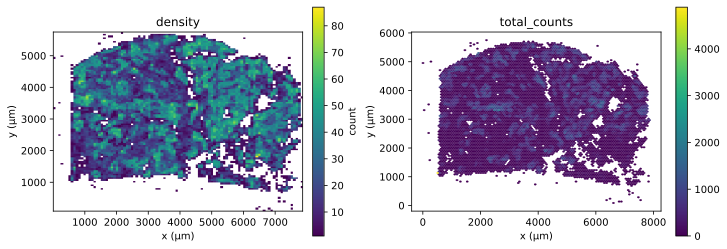

In [10]:
# Rasterised cell density — faster than points for large datasets.
ab.pl.raster(data) | ab.pl.raster(data, bin_shape='hex', color='total_counts')

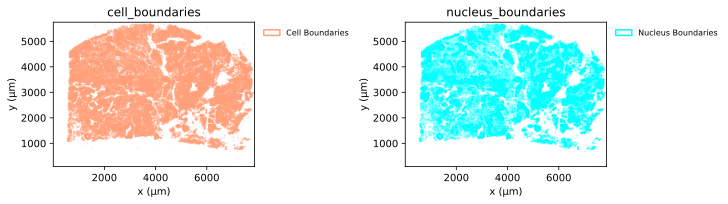

In [11]:
ab.pl.boundaries(data) | ab.pl.boundaries(data, boundaries_key='nucleus_boundaries')

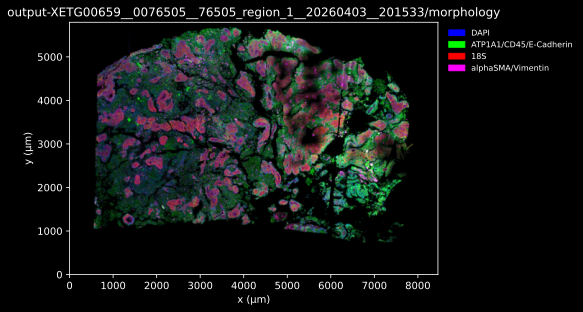

In [12]:
ab.pl.image(data)

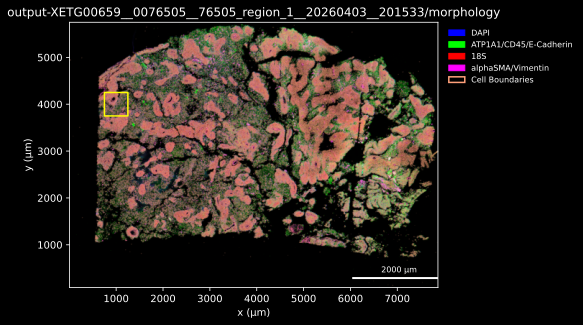

In [13]:
ab.pl.image(data, scale_bar=True) + ab.pl.boundaries(data, alpha=0.2) + ab.pl.annotation(
    ab.pl.rectangle((1000., 4000.), 500., 500.)
)

In [14]:
cropped = ab.pp.crop(data, ab.pl.rectangle((1000., 4000.), 500., 500.), inplace=False)
ab.pl.image(cropped, scale_bar=True) + ab.pl.boundaries(cropped) + ab.pl.boundaries(cropped, boundaries_key='nucleus_boundaries')

## Spatial Neighbor Graph

In [11]:
# Build a KNN spatial neighbor graph from cell centroids (required for micronuclei detection).
ab.tl.spatial_neighbors(data, n_neighbors=15)
import numpy as np
dists = data['xenium'].obsp['spatial_neighbors_distances']
mean_dist = dists.data.mean()
print(f'Mean nearest-neighbor distance: {mean_dist:.1f} µm')
ab.summary(data)

Mean nearest-neighbor distance: 12.3 µm


MuData Summary
==================================================
Modalities:
  xenium (default): 151,710 cells × 5,051 vars
Extent: x=[554, 7867] µm  y=[736, 5675] µm
Libraries (1):
  output-XETG00659__0076505__76505_region_1__20260403__201533: C:\Users\Austin\PycharmProjects\astrolabe\output-XETG00659__0076505__76505_region_1__20260403__201533  (1 image(s))
Stats: median counts=144, median genes=122, mean area=85.2 µm²
Obs columns:
  QC: cell_area, nucleus_area, transcript_counts, nucleus_count, unassigned_codeword_total, deprecated_codeword_total, genomic_control_probe_total, negative_control_codeword_total, negative_control_probe_total, any_negative_control_probe_total, n_unassigned_codewords, n_deprecated_codewords, n_genomic_control_probes, n_negative_control_codewords, n_negative_control_probes, n_any_negative_control_probes, pct_unassigned_codewords, pct_deprecated_codewords, pct_genomic_control_probes, pct_negative_control_codewords, pct_negative_control_probes, pct_any_negative_control_probes, pct_counts_control, n_genes_by_counts, log1p_n_genes_by_counts, total_counts, log1p_total_counts, pct_counts_in_top_50_genes, pct_counts_in_top_100_genes, pct_counts_in_top_200_genes, pct_counts_in_top_500_genes, nucleus_to_cell_area_ratio, has_nucleus
  Other: control_probe_counts, control_codeword_counts
Graph/seg: cell_boundaries, nucleus_boundaries, spatial_graph
Workflow: QC → log1p

## Micronuclei Detection

In [6]:
# Identify cells whose nucleus is small enough to be a micronucleus and that are
# close to a larger primary nucleus.  Thresholds may need tuning per dataset.
mapping = ab.tl.identify_micronuclei(data, max_nucleus_area=10.0, max_distance_um=4.0)
n_micro = len(mapping)
print(f'Identified {n_micro} micronuclei ({n_micro / data["xenium"].n_obs * 100:.1f}% of cells)')
mapping.head()

Identified 230 micronuclei (0.1% of cells)


aahpgemb-1    aahonfhl-1
achkjlcp-1    lfmlpcag-1
apejcidm-1    kdieobde-1
baeacpmg-1    halghhni-1
bbchmmge-1    bbchmimm-1
Name: primary_cell_id, dtype: object

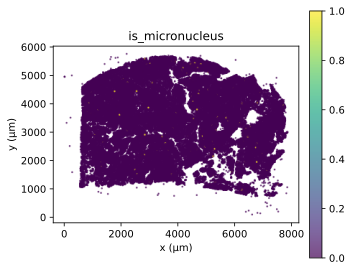

In [17]:
# Spatial distribution of micronuclei (red) vs primary cells (dark grey).
ab.pl.points(data, color='is_micronucleus')

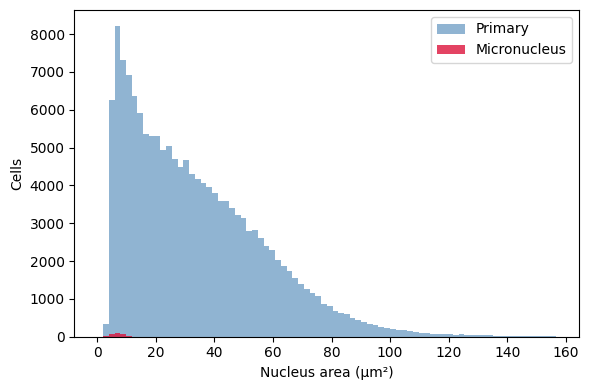

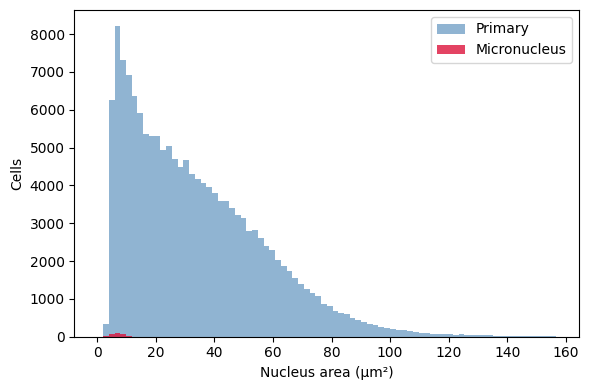

In [18]:
# Nucleus area distribution: micronuclei should cluster at the low end.
import matplotlib.pyplot as plt
import numpy as np
xen = data['xenium']
# Shared bin edges — drop NaN (cells with no detected nucleus) before computing range.
all_areas = xen.obs['nucleus_area'].dropna()
bins = np.linspace(0, float(np.quantile(all_areas, 0.999)), 81)
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(xen.obs.loc[~xen.obs['is_micronucleus'], 'nucleus_area'].dropna(),
        bins=bins, alpha=0.6, label='Primary', color='steelblue')
ax.hist(xen.obs.loc[xen.obs['is_micronucleus'], 'nucleus_area'].dropna(),
        bins=bins, alpha=0.8, label='Micronucleus', color='crimson')
ax.set_xlabel('Nucleus area (µm²)')
ax.set_ylabel('Cells')
ax.legend()
plt.tight_layout()
fig

## Merge Micronuclei

In [19]:
# Merge micronuclei into a separate modality aligned with the primary cells.
# merged['xenium']      — primary nuclear counts (micronuclei rows removed)
# merged['micronuclei'] — per-cell sum of micronuclear counts (same obs_names, zeros where no micronuclei)
merged = ab.tl.merge_micronuclei(data, mapping)

n_before = len(mapping) + merged['xenium'].n_obs
print(f"Before: {n_before} cells")
print(f"After:  {merged['xenium'].n_obs} primary cells  ({len(mapping)} micronuclei absorbed)")
print(f"Cells with at least one micronucleus: {(merged['micronuclei'].obs['micronuclei_count'] > 0).sum()}")
merged

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\mudata\_core\mudata.py:1416: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=0, join_common=join_common)


Before: 162345 cells
After:  162115 primary cells  (230 micronuclei absorbed)
Cells with at least one micronucleus: 229


MuData object with n_obs × n_vars = 162115 × 10102
  uns:	'spatial', 'astrolabe_schema_version', 'default_modality'
  2 modalities
    xenium:	162115 × 5051
      obs:	'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'is_micronucleus', 'micronucleus_of'
      var:	'gene_id', 'feature_type', 'genome', 'is_control_probe', 'is_control', 'mean_qv', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
      uns:	'spatial', 'astrolabe_schema_version', 'transcripts', 'control_probe_summary', 'spatial_neighbors', 'neighbors'
      obsm:	'spatial', 'cell_boundaries', 'nucleus_boundaries'
      obsp:	'spatial_neighbors_connectivities', 'spatial_neighbors_distances'
    micronuclei:	162115 × 5051
      obs:	'micronuclei_count'
      var:	'gene_id', 'feature_type', 'genome', 'is_control_probe', 'is_control', 'mean_qv', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
      uns:	'micronuclei_merged'
      obsm:	'spatial', 'cell_boundaries', 'nucleus_boundaries'

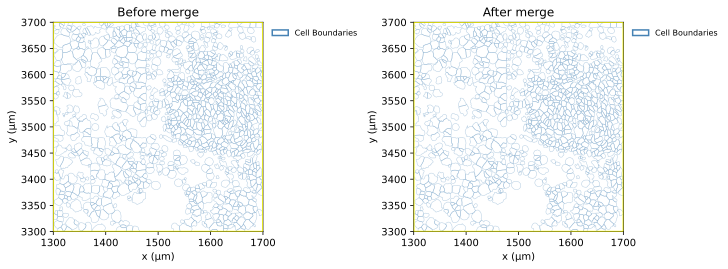

In [20]:
# Compare cell boundaries before and after merging in a small ROI.
# After merging, primary cell boundaries expand to include their micronuclei territory.
roi = ab.pl.rectangle((1500., 3500.), 400., 400.)
cropped_before = ab.pp.crop(data['xenium'],    roi, inplace=False)
cropped_after  = ab.pp.crop(merged['xenium'],  roi, inplace=False)
(
    ab.pl.boundaries(cropped_before, alpha=0.4, color='steelblue', title='Before merge')
    + ab.pl.annotation(roi)
    | ab.pl.boundaries(cropped_after, alpha=0.4, color='steelblue', title='After merge')
    + ab.pl.annotation(roi)
)

## Nuclear vs Micronuclear Transcripts

In [21]:
import numpy as np
import pandas as pd

# merged['xenium'] and merged['micronuclei'] share the same obs_names.
# Restrict to cells that actually have micronuclei so the comparison is meaningful.
has_micro = merged['micronuclei'].obs['micronuclei_count'] > 0
xen_sub = merged['xenium'][has_micro]
mic_sub = merged['micronuclei'][has_micro]

print(f"Comparing {has_micro.sum()} primary cells that absorbed at least one micronucleus")
print(f"Primary nuclear counts  (X):  {xen_sub.X.sum():,.0f} total transcripts")
print(f"Micronuclear counts (X): {mic_sub.X.sum():,.0f} total transcripts")

Comparing 229 primary cells that absorbed at least one micronucleus
Primary nuclear counts  (X):  41,509 total transcripts
Micronuclear counts (X): 10,766 total transcripts


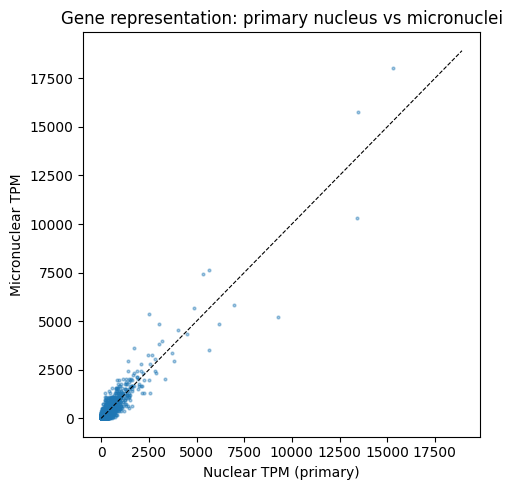

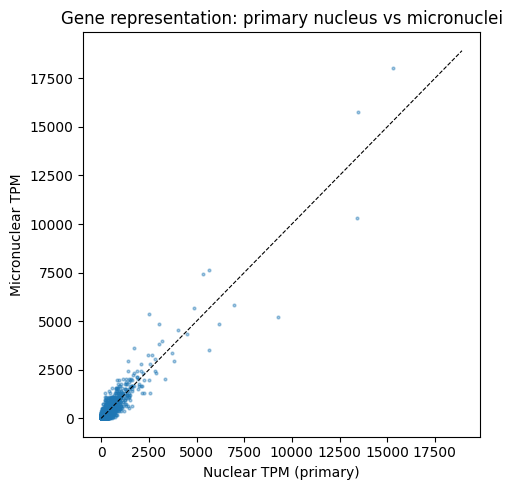

In [22]:
import matplotlib.pyplot as plt

# Per-gene TPM in each compartment (summed across cells with micronuclei)
def to_tpm(X_matrix):
    counts = np.asarray(X_matrix.sum(axis=0), dtype=np.float64).ravel()
    total = counts.sum()
    return counts / total * 1e6 if total > 0 else counts

nuclear_tpm    = to_tpm(xen_sub.X)
micronucl_tpm  = to_tpm(mic_sub.X)
gene_names     = list(xen_sub.var_names)

comparison = pd.DataFrame({
    'gene':          gene_names,
    'nuclear_tpm':   nuclear_tpm,
    'micronuclear_tpm': micronucl_tpm,
})
comparison['ratio'] = (comparison['micronuclear_tpm'] + 1) / (comparison['nuclear_tpm'] + 1)

# Scatter: nuclear TPM vs micronuclear TPM — diagonal = equal abundance.
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(comparison['nuclear_tpm'], comparison['micronuclear_tpm'], s=4, alpha=0.4)
lim = max(comparison['nuclear_tpm'].max(), comparison['micronuclear_tpm'].max(), 1.0) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=0.8)
ax.set_xlabel('Nuclear TPM (primary)')
ax.set_ylabel('Micronuclear TPM')
ax.set_title('Gene representation: primary nucleus vs micronuclei')
plt.tight_layout()
fig

Top 20 micronucleus-enriched genes:
   gene  nuclear_tpm  micronuclear_tpm      ratio
 SELPLG          0.0        371.540033 372.540033
   CDH3          0.0        278.655025 279.655025
 IL17RA          0.0        278.655025 279.655025
   NAT1          0.0        278.655025 279.655025
SLC22A5          0.0        278.655025 279.655025
   SSX1          0.0        278.655025 279.655025
   TP73          0.0        278.655025 279.655025
   AIRE          0.0        185.770017 186.770017
 AVPR1B          0.0        185.770017 186.770017
   BDNF          0.0        185.770017 186.770017
    CA9          0.0        185.770017 186.770017
  CASQ2          0.0        185.770017 186.770017
 CYP4F2          0.0        185.770017 186.770017
  ELAC1          0.0        185.770017 186.770017
  FOXP1          0.0        185.770017 186.770017
   GSX2          0.0        185.770017 186.770017
 HCRTR2          0.0        185.770017 186.770017
  ITGAL          0.0        185.770017 186.770017
  MAP1A       

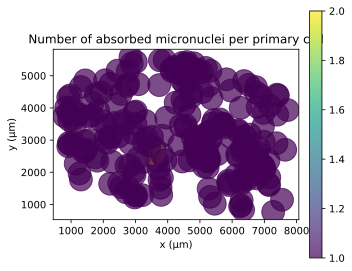

In [23]:
# Top genes enriched in micronuclei relative to primary nuclei.
print("Top 20 micronucleus-enriched genes:")
print(
    comparison.nlargest(20, 'ratio')
    [['gene', 'nuclear_tpm', 'micronuclear_tpm', 'ratio']]
    .to_string(index=False)
)

# Spatial plot: where are the micronuclear transcripts concentrated?
# merged['micronuclei'].obsm['spatial'] holds the mean centroid of each cell's micronuclei.
ab.pl.points(merged['micronuclei'][has_micro], color='micronuclei_count',
             title='Number of absorbed micronuclei per primary cell')

## Paired DE: Nucleus vs Micronuclei

In [24]:
import numpy as np
import pandas as pd
from scipy import stats, sparse

# xen_sub / mic_sub defined in the cell above (1 200 cells with micronuclei).
# Library-size-normalise each cell to 1 e4 counts then log1p — keeps per-cell
# depth from dominating the comparison.
def _lognorm(X):
    arr = np.asarray(X.todense() if sparse.issparse(X) else X, dtype=np.float32)
    lib = arr.sum(axis=1, keepdims=True)
    lib[lib == 0] = 1.0
    return np.log1p(arr / lib * 1e4)

nuc_ln = _lognorm(xen_sub.X)   # (n_cells, n_genes)
mic_ln = _lognorm(mic_sub.X)

# Vectorised paired t-test across all genes at once.
t_stat, pvals_raw = stats.ttest_rel(mic_ln, nuc_ln, axis=0)

# log2FC as mean difference in log-normalised space (divided by ln 2).
lfc = (mic_ln.mean(axis=0) - nuc_ln.mean(axis=0)) / np.log(2)

# Replace NaN p-values (genes with zero variance in both compartments) with 1.
pvals_raw = np.where(np.isnan(pvals_raw), 1.0, pvals_raw)

# Benjamini–Hochberg correction (scipy ≥ 1.11).
pvals_adj = stats.false_discovery_control(pvals_raw, method='bh')

de = pd.DataFrame(
    {'log2fc': lfc, 'pval': pvals_raw, 'pval_adj': pvals_adj},
    index=xen_sub.var_names,
).sort_values('pval_adj')

sig = de[(de['pval_adj'] < 0.05) & (de['log2fc'].abs() > 0.5)]
print(f"{len(sig)} significant genes  (FDR < 5 %, |log2FC| > 0.5)")

print("\nTop 10 micronucleus-enriched:")
print(sig.nlargest(10, 'log2fc')[['log2fc', 'pval_adj']].to_string())
print("\nTop 10 nucleus-enriched:")
print(sig.nsmallest(10, 'log2fc')[['log2fc', 'pval_adj']].to_string())

73 significant genes  (FDR < 5 %, |log2FC| > 0.5)

Top 10 micronucleus-enriched:
             log2fc  pval_adj
gene_name                    
KPNA2     -0.501765  0.033341
RTCB      -0.511999  0.003363
MX1       -0.520267  0.008473
PDIA3     -0.523866  0.019129
DVL3      -0.525722  0.029581
GMPS      -0.526730  0.033360
PTPN11    -0.528146  0.001906
DDX52     -0.528414  0.003363
HADHA     -0.530886  0.012196
MCCC1     -0.533232  0.001183

Top 10 nucleus-enriched:
             log2fc      pval_adj
gene_name                        
SOX2-OT   -3.182414  2.719210e-12
SOST      -2.260150  7.934009e-09
NTS       -1.548215  6.990722e-06
YWHAZ     -1.345869  2.496937e-05
ALG11     -1.215670  4.420725e-05
SNHG15    -1.176744  4.658236e-04
EEF1G     -1.117386  4.183170e-03
SOX2      -1.043732  3.158124e-04
LDHA      -1.009805  4.658236e-04
RAC1      -1.000836  3.158124e-04


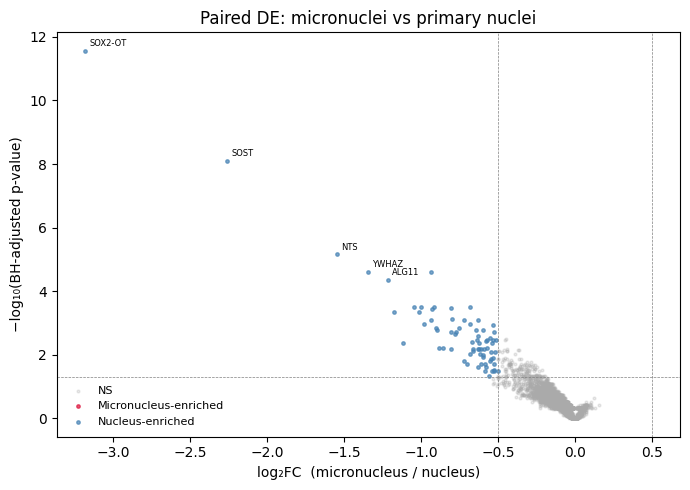

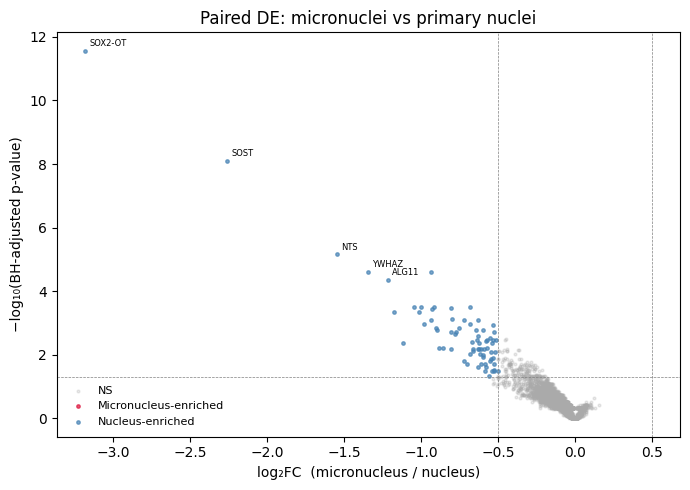

In [25]:
import matplotlib.pyplot as plt

sig_up   = (de['pval_adj'] < 0.05) & (de['log2fc'] >  0.5)
sig_down = (de['pval_adj'] < 0.05) & (de['log2fc'] < -0.5)
ns_mask  = ~(sig_up | sig_down)

y = -np.log10(de['pval_adj'].clip(lower=1e-300))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(de.loc[ns_mask,  'log2fc'], y[ns_mask],  s=4, alpha=0.25, color='#aaaaaa', label='NS', rasterized=True)
ax.scatter(de.loc[sig_up,   'log2fc'], y[sig_up],   s=6, alpha=0.7,  color='crimson',   label='Micronucleus-enriched', rasterized=True)
ax.scatter(de.loc[sig_down, 'log2fc'], y[sig_down], s=6, alpha=0.7,  color='steelblue', label='Nucleus-enriched', rasterized=True)

for gene in de[sig_up].nlargest(5, 'log2fc').index.tolist() + de[sig_down].nsmallest(5, 'log2fc').index.tolist():
    ax.annotate(gene, (de.loc[gene, 'log2fc'], y[gene]),
                fontsize=6, ha='left', va='bottom', xytext=(3, 2), textcoords='offset points')

ax.axvline( 0.5, color='gray', lw=0.5, ls='--')
ax.axvline(-0.5, color='gray', lw=0.5, ls='--')
ax.axhline(-np.log10(0.05), color='gray', lw=0.5, ls='--')
ax.set_xlabel('log₂FC  (micronucleus / nucleus)')
ax.set_ylabel('−log₁₀(BH-adjusted p-value)')
ax.set_title('Paired DE: micronuclei vs primary nuclei')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
fig